# TP 1 — Prédiction du risque d'incendie

**Objectif.** Construire un système capable de prédire si une zone présente un risque d'incendie (`Fire` = 1) à partir de variables météo, spatiales, temporelles et d'indices de végétation.

**Jeu de données.** `DatasetMorocco - Copie.csv` (Maroc, janvier–mai 2022) :
température, humidité, précipitations, vent, pression, NDVI, NDMI, NBR, latitude, longitude, date/heure d'acquisition, cible `Fire`.

**Plan.**
1. Analyse exploratoire, outliers, valeurs manquantes, corrélations, feature engineering, encodage, normalisation, split sans fuite
2. Entraînement : Extra Trees, HistGradientBoosting, XGBoost, LightGBM, Random Forest, MLP
3. Validation croisée stratifiée, comparaison de métriques, matrices de confusion, SHAP, erreurs du meilleur modèle


## 0. Imports et configuration

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
np.random.seed(42)

ROOT = Path(".")
DATA_PATH = ROOT / "DatasetMorocco - Copie.csv"
FIG_DIR = ROOT / "figures"
OUT_DIR = ROOT / "outputs"
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42


## 1. Chargement et premier aperçu

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dimensions :", df.shape)
print("\nColonnes :", list(df.columns))
display(df.head())
display(df.dtypes.to_frame("dtype"))
print("Cible Fire :")
print(df["Fire"].value_counts())
print("\nTaux de feux :", df["Fire"].mean().round(3))


Dimensions : (299, 15)

Colonnes : ['Fire', 'acq_date', 'acq_time', 'humidity_percent', 'precipitation_mm', 'pressure_hPa', 'temperature_C', 'wind_direction_deg', 'wind_speed_mps', 'longitude', 'latitude', 'NDVI', 'NDMI', 'NDWI', 'NBR']


,Fire,acq_date,acq_time,humidity_percent,precipitation_mm,pressure_hPa,temperature_C,wind_direction_deg,wind_speed_mps,longitude,latitude,NDVI,NDMI,NDWI,NBR
0,0,2022-01-01,221,50.305471,0.0,943.095352,12.053644,298.354195,1.211075,-3.435720,34.505224,0.118925,-0.202849,-0.271944,-0.130924
1,1,2022-01-01,221,71.519658,0.0,968.825352,7.565363,169.009182,2.057297,-5.118192,33.945032,-0.333333,0.176471,0.795918,0.333333
2,1,2022-01-01,1340,61.788530,0.0,1019.161758,19.497369,312.008412,0.708083,-6.166009,34.877394,0.054914,-0.242592,-0.119941,-0.263492
3,0,2022-01-02,201,39.120900,0.0,901.557969,8.234415,97.171733,0.543159,-4.291256,34.755224,0.291355,-0.254314,-0.456077,-0.177430
4,0,2022-01-02,1321,43.353296,0.0,973.095703,20.696130,343.057416,1.462190,-6.062857,33.629880,0.258453,0.047219,-0.275808,0.149858


,dtype
Fire,int64
acq_date,str
acq_time,int64
humidity_percent,float64
precipitation_mm,float64
pressure_hPa,float64
temperature_C,float64
wind_direction_deg,float64
wind_speed_mps,float64
longitude,float64


Cible Fire :
Fire
1    181
0    118
Name: count, dtype: int64

Taux de feux : 0.605


### 1.1 Analyse exploratoire approfondie

Les colonnes brutes ne correspondent pas exactement à l'énoncé : la date et l'heure sont dans `acq_date` / `acq_time` (format HHMM, ex. `221` = 02:21). `NDWI` et `wind_direction_deg` sont aussi disponibles et seront utiles.


In [3]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())
print("\nDoublons exacts :", df.duplicated().sum())
display(df.describe().T.round(3))

df["acq_date"] = pd.to_datetime(df["acq_date"])
print("Periode :", df["acq_date"].min().date(), "->", df["acq_date"].max().date())
print("Mois :")
print(df["acq_date"].dt.month.value_counts().sort_index())


Valeurs manquantes par colonne :
Fire                  0
acq_date              0
acq_time              0
humidity_percent      0
precipitation_mm      0
pressure_hPa          0
temperature_C         0
wind_direction_deg    0
wind_speed_mps        0
longitude             0
latitude              0
NDVI                  0
NDMI                  0
NDWI                  0
NBR                   0
dtype: int64

Doublons exacts : 0


,count,mean,std,min,25%,50%,75%,max
Fire,299.0,0.605,0.490,0.000,0.000,1.000,1.000,1.000
acq_time,299.0,848.405,561.680,110.000,213.000,1250.000,1333.000,1430.000
humidity_percent,299.0,59.705,25.173,14.367,39.009,59.114,84.461,100.002
precipitation_mm,299.0,0.034,0.193,0.000,0.000,0.000,0.001,2.486
pressure_hPa,299.0,961.755,45.855,841.556,928.309,969.894,998.143,1024.286
temperature_C,299.0,14.086,5.490,0.761,9.457,14.925,18.442,28.867
wind_direction_deg,299.0,169.475,104.004,3.482,75.892,168.791,265.011,354.958
wind_speed_mps,299.0,2.024,1.266,0.218,1.340,1.718,2.373,9.757
longitude,299.0,-4.973,1.093,-6.681,-5.759,-5.211,-4.266,-2.521
latitude,299.0,34.602,0.601,33.544,33.996,34.717,35.003,35.874


Periode : 2022-01-01 -> 2022-05-07
Mois :
acq_date
1     94
2    102
3     31
4     52
5     20
Name: count, dtype: int64


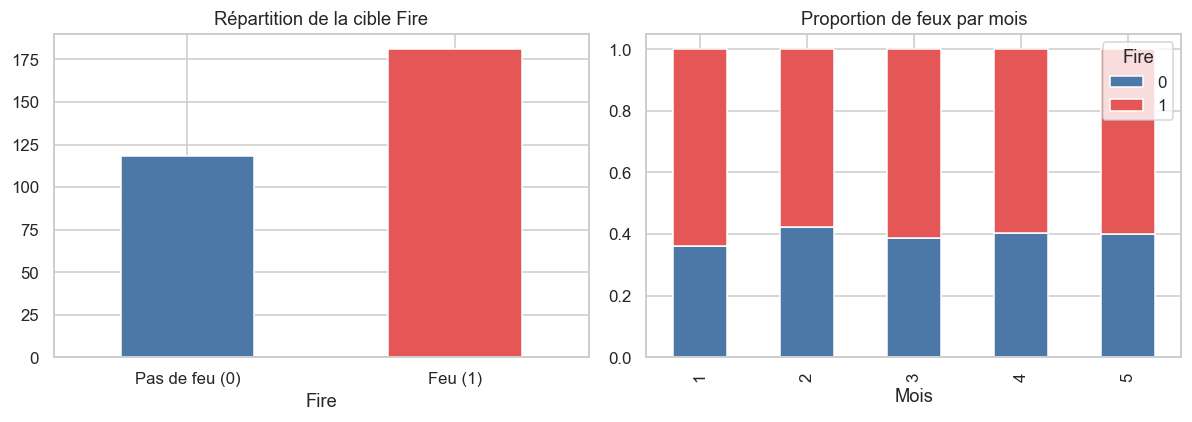

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["Fire"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4c78a8", "#e45756"]
)
axes[0].set_title("Répartition de la cible Fire")
axes[0].set_xticklabels(["Pas de feu (0)", "Feu (1)"], rotation=0)

mois = df["acq_date"].dt.month
pd.crosstab(mois, df["Fire"], normalize="index").plot(
    kind="bar", stacked=True, ax=axes[1], color=["#4c78a8", "#e45756"]
)
axes[1].set_title("Proportion de feux par mois")
axes[1].set_xlabel("Mois")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_cible_et_mois.png", bbox_inches="tight")
plt.show()


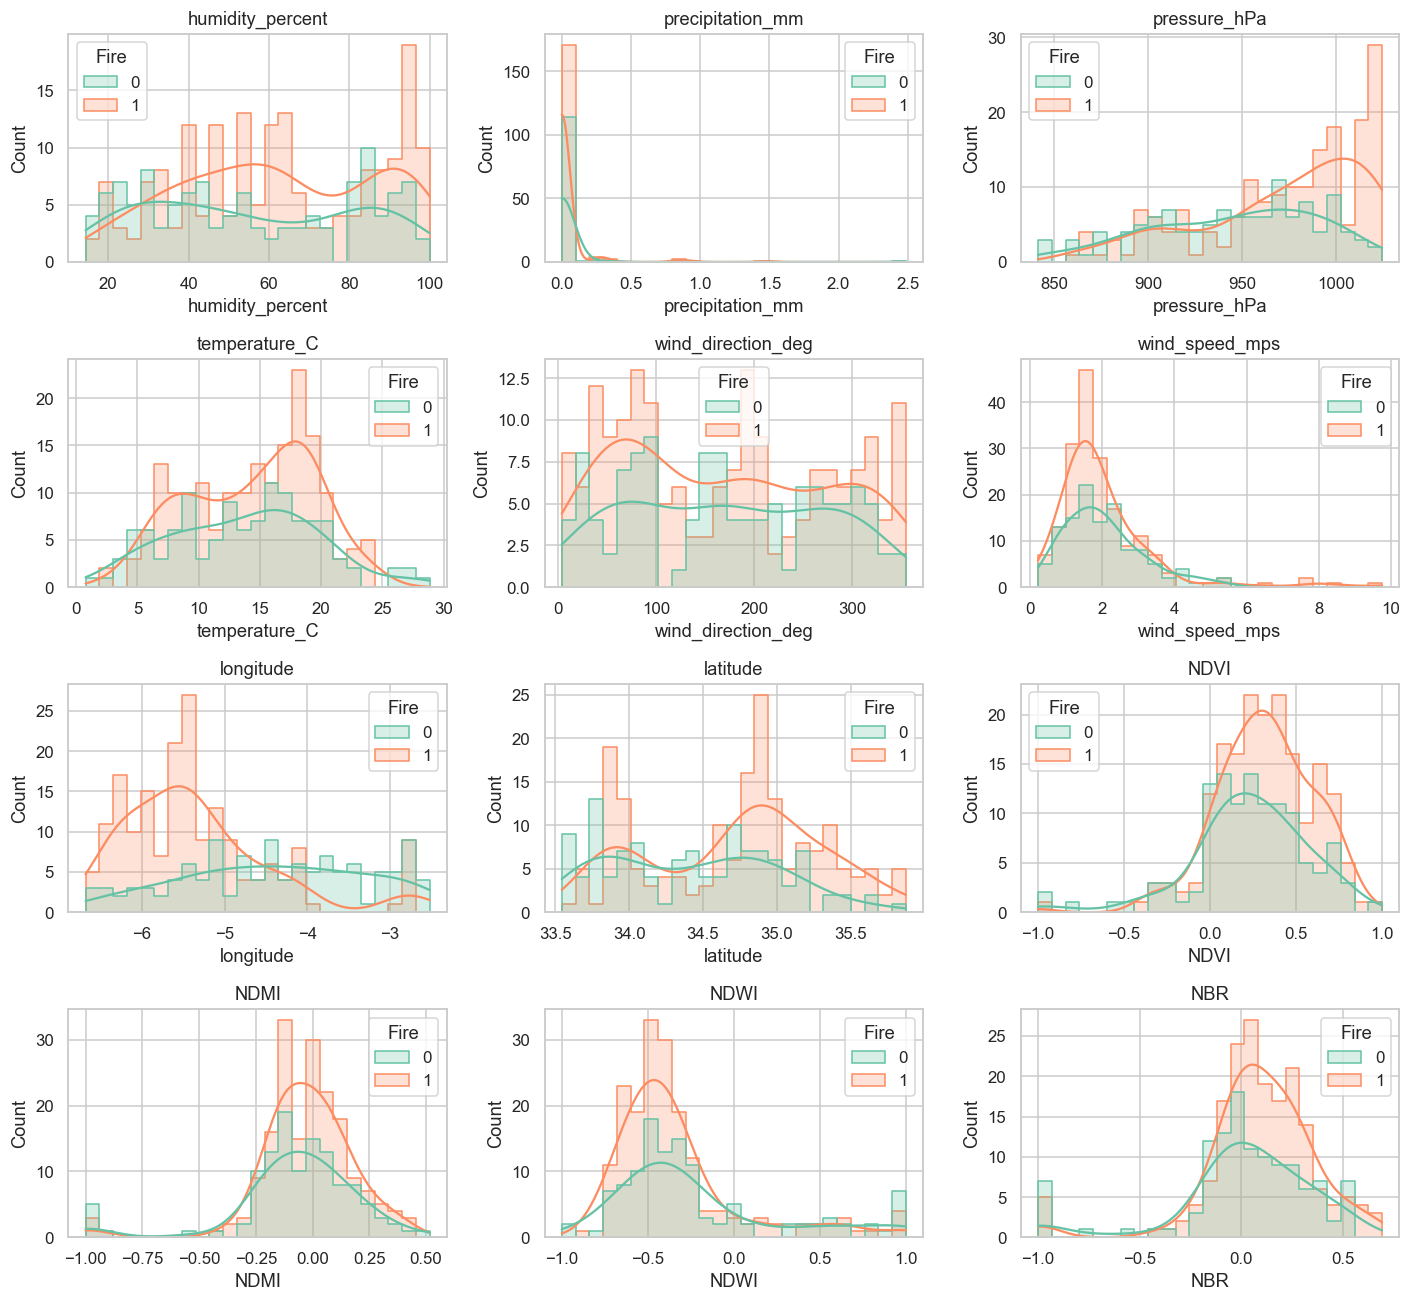

In [5]:
num_cols_raw = [
    "humidity_percent",
    "precipitation_mm",
    "pressure_hPa",
    "temperature_C",
    "wind_direction_deg",
    "wind_speed_mps",
    "longitude",
    "latitude",
    "NDVI",
    "NDMI",
    "NDWI",
    "NBR",
]

fig, axes = plt.subplots(4, 3, figsize=(13, 12))
for ax, col in zip(axes.ravel(), num_cols_raw):
    sns.histplot(df, x=col, hue="Fire", ax=ax, bins=25, kde=True, element="step")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_distributions.png", bbox_inches="tight")
plt.show()


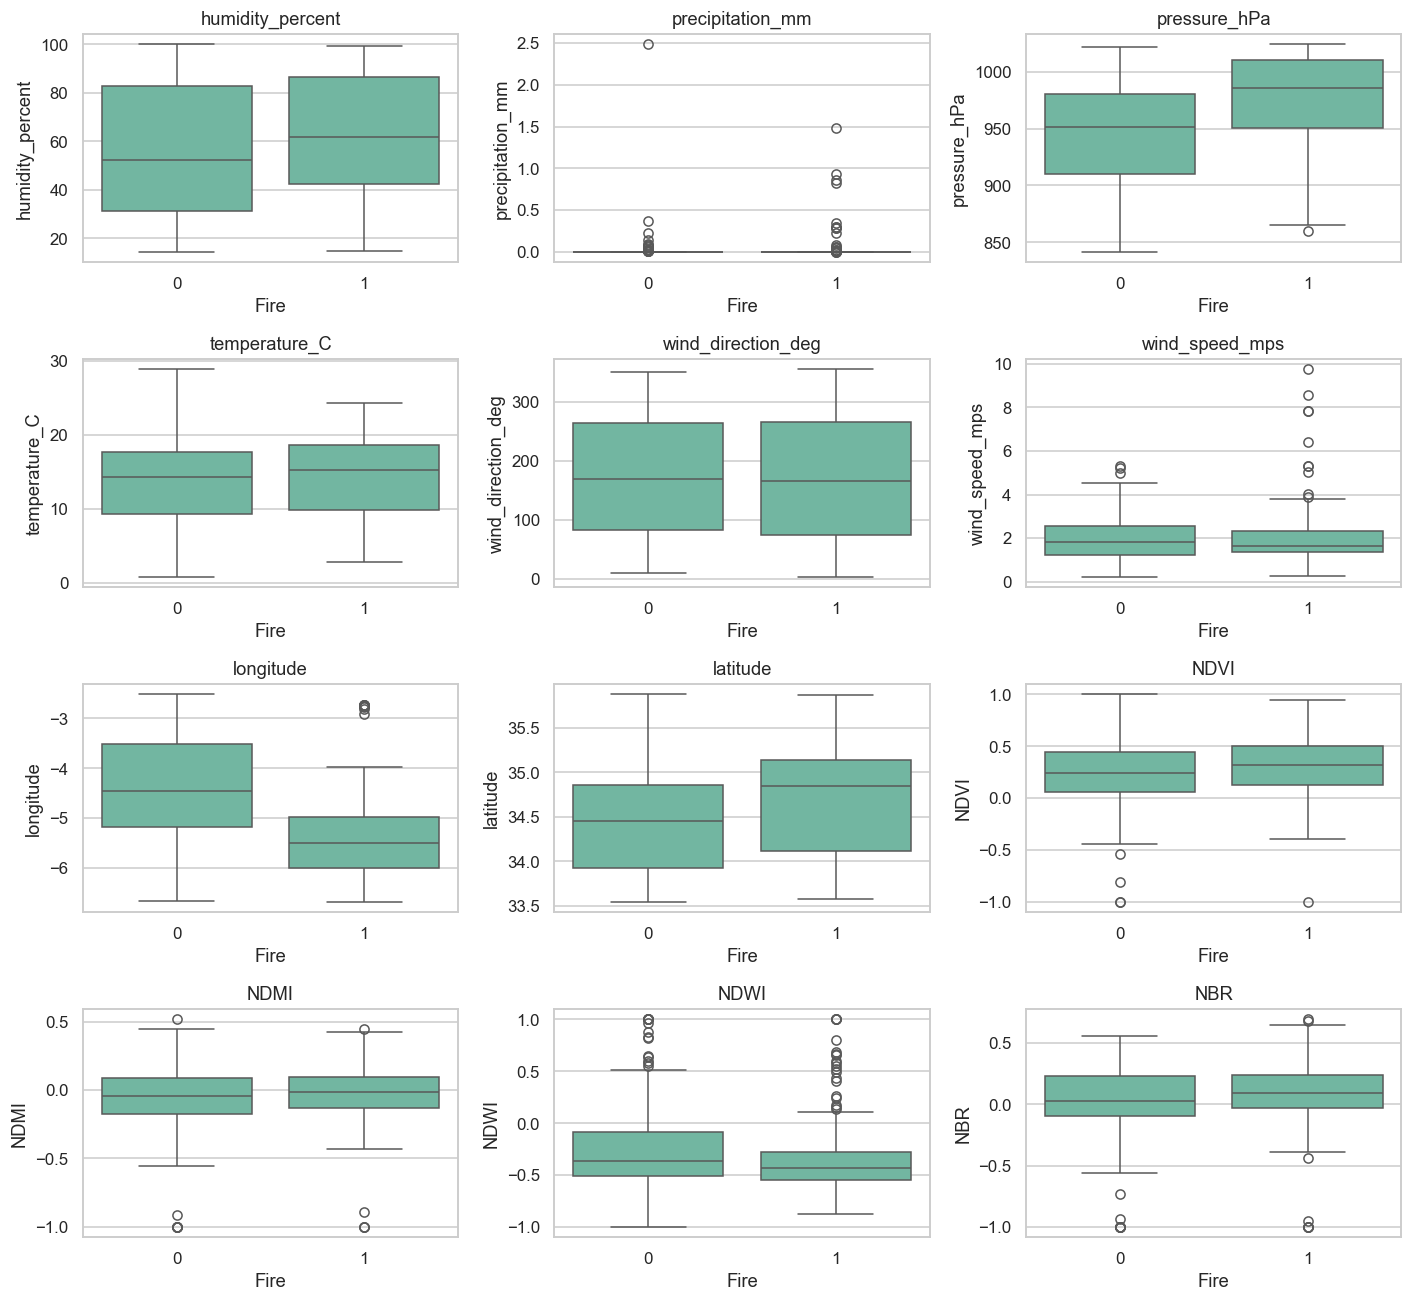

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(13, 12))
for ax, col in zip(axes.ravel(), num_cols_raw):
    sns.boxplot(data=df, x="Fire", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_boxplots.png", bbox_inches="tight")
plt.show()


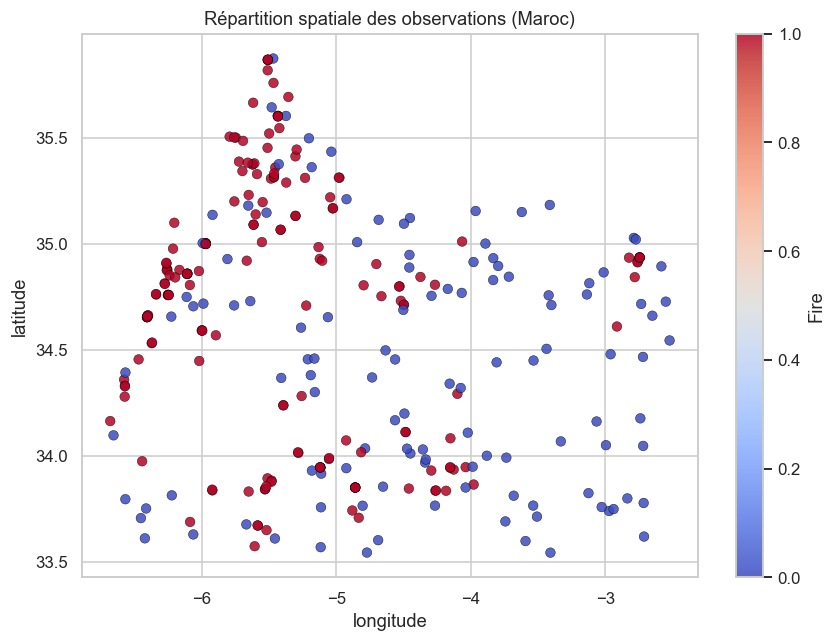

In [7]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["Fire"],
    cmap="coolwarm",
    alpha=0.85,
    s=40,
    edgecolors="k",
    linewidths=0.3,
)
plt.colorbar(sc, label="Fire")
plt.title("Répartition spatiale des observations (Maroc)")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_carte.png", bbox_inches="tight")
plt.show()


### 1.2 Détection des valeurs aberrantes

Deux familles d'anomalies :

1. **Domaine physique** : humidité > 100 %, indices de végétation exactement égaux à −1 (souvent des pixels nodata / nuages).
2. **Statistique (IQR)** : points hors \([Q1 - 1{,}5\,\mathrm{IQR},\ Q3 + 1{,}5\,\mathrm{IQR}]\).

Les bornes IQR seront **estimées uniquement sur le train** plus loin, pour éviter la fuite. Ici on diagnostique sur tout le jeu.


In [8]:
print("Humidité > 100 % :", (df["humidity_percent"] > 100).sum())
print("Humidité < 0 %   :", (df["humidity_percent"] < 0).sum())
print("Précipitations < 0 :", (df["precipitation_mm"] < 0).sum())

for c in ["NDVI", "NDMI", "NDWI", "NBR"]:
    n_m1 = (df[c] == -1).sum()
    n_p1 = (df[c] == 1).sum()
    print(f"{c}: == -1 -> {n_m1} | == 1 -> {n_p1}")


def iqr_report(frame, cols):
    rows = []
    for col in cols:
        q1, q3 = frame[col].quantile(0.25), frame[col].quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (frame[col] < low) | (frame[col] > high)
        rows.append(
            {
                "variable": col,
                "Q1": q1,
                "Q3": q3,
                "borne_inf": low,
                "borne_sup": high,
                "n_outliers": int(mask.sum()),
                "pct": 100 * mask.mean(),
            }
        )
    return pd.DataFrame(rows).round(3)


rep = iqr_report(df, num_cols_raw)
display(rep)
rep.to_csv(OUT_DIR / "outliers_iqr.csv", index=False)


Humidité > 100 % : 1
Humidité < 0 %   : 0
Précipitations < 0 : 0
NDVI: == -1 -> 3 | == 1 -> 1
NDMI: == -1 -> 8 | == 1 -> 0
NDWI: == -1 -> 2 | == 1 -> 10
NBR: == -1 -> 10 | == 1 -> 0


,variable,Q1,Q3,borne_inf,borne_sup,n_outliers,pct
0,humidity_percent,39.009,84.461,-29.168,152.638,0,0.000
1,precipitation_mm,0.000,0.001,-0.002,0.003,53,17.726
2,pressure_hPa,928.309,998.143,823.559,1102.894,0,0.000
3,temperature_C,9.457,18.442,-4.021,31.920,0,0.000
4,wind_direction_deg,75.892,265.011,-207.786,548.690,0,0.000
5,wind_speed_mps,1.340,2.373,-0.211,3.924,17,5.686
6,longitude,-5.759,-4.266,-7.999,-2.026,0,0.000
7,latitude,33.996,35.003,32.486,36.514,0,0.000
8,NDVI,0.106,0.485,-0.464,1.055,5,1.672
9,NDMI,-0.140,0.091,-0.486,0.437,14,4.682


### 1.3 Gestion des valeurs manquantes

Aucune valeur `NaN` n'est présente dans le CSV. En revanche, les **indices satellites à −1** sont traités comme manquants (nodata). Ils seront imputés **après le split**, avec des statistiques du train seulement.

L'humidité > 100 % est clipée à 100 (contrainte physique, pas de fuite).


In [9]:
df_clean = df.copy()
df_clean.loc[df_clean["humidity_percent"] > 100, "humidity_percent"] = 100.0

SENTINEL_COLS = ["NDVI", "NDMI", "NDWI", "NBR"]
for c in SENTINEL_COLS:
    n = (df_clean[c] == -1).sum()
    df_clean.loc[df_clean[c] == -1, c] = np.nan
    print(f"{c}: {n} sentinelles -1 remplacées par NaN")

print("\nManquants après traitement domaine :")
print(df_clean.isna().sum()[lambda s: s > 0])


NDVI: 3 sentinelles -1 remplacées par NaN
NDMI: 8 sentinelles -1 remplacées par NaN
NDWI: 2 sentinelles -1 remplacées par NaN
NBR: 10 sentinelles -1 remplacées par NaN

Manquants après traitement domaine :
NDVI     3
NDMI     8
NDWI     2
NBR     10
dtype: int64


### 1.4 Analyse de corrélation

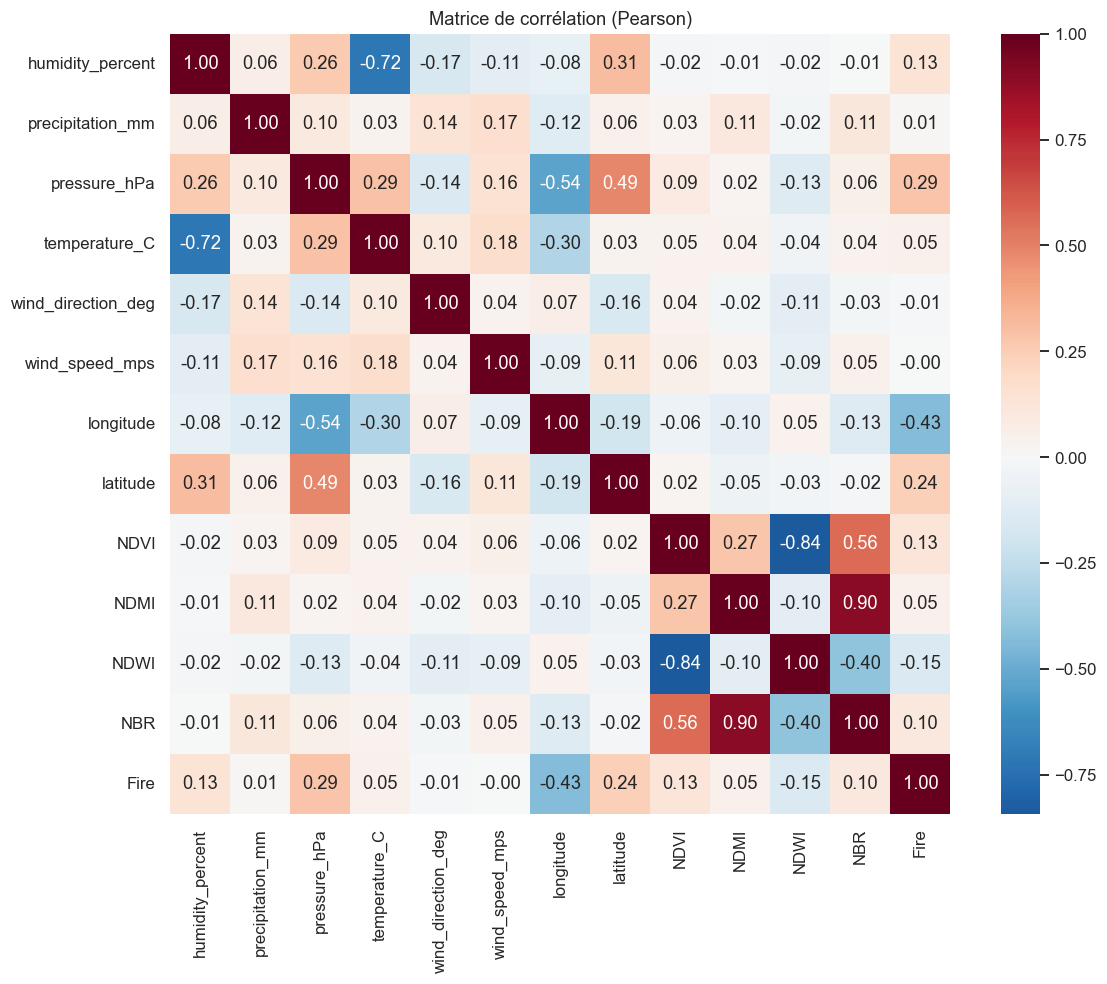

Corrélation avec Fire (valeur absolue, triée) :
longitude             0.431
pressure_hPa          0.285
latitude              0.242
NDWI                  0.151
humidity_percent      0.131
NDVI                  0.128
NBR                   0.102
NDMI                  0.052
temperature_C         0.051
wind_direction_deg    0.009
precipitation_mm      0.008
wind_speed_mps        0.004
Name: Fire, dtype: float64


In [10]:
corr_cols = num_cols_raw + ["Fire"]
corr = df_clean[corr_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Matrice de corrélation (Pearson)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_correlation.png", bbox_inches="tight")
plt.show()

print("Corrélation avec Fire (valeur absolue, triée) :")
print(corr["Fire"].drop("Fire").abs().sort_values(ascending=False).round(3))


## 2. Feature engineering

Toutes les transformations ci-dessous sont **ligne à ligne** (pas de moyenne globale) : elles peuvent être appliquées avant le split sans fuite.

- `mois`, `heure` extraits de la date / `acq_time`
- encodage **cyclique** (sin/cos) pour mois et heure
- saison et période de la journée (catégorielles)
- composantes du vent \(u, v\)
- proxies de sécheresse / stress thermique
- interactions d'indices de végétation


In [11]:
def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    if not np.issubdtype(out["acq_date"].dtype, np.datetime64):
        out["acq_date"] = pd.to_datetime(out["acq_date"])

    out["mois"] = out["acq_date"].dt.month.astype(int)
    out["heure"] = (out["acq_time"] // 100).astype(int)
    out["heure"] = out["heure"].clip(0, 23)

    out["mois_sin"] = np.sin(2 * np.pi * out["mois"] / 12)
    out["mois_cos"] = np.cos(2 * np.pi * out["mois"] / 12)
    out["heure_sin"] = np.sin(2 * np.pi * out["heure"] / 24)
    out["heure_cos"] = np.cos(2 * np.pi * out["heure"] / 24)

    def saison(m):
        if m in (12, 1, 2):
            return "hiver"
        if m in (3, 4, 5):
            return "printemps"
        if m in (6, 7, 8):
            return "ete"
        return "automne"

    out["saison"] = out["mois"].map(saison)
    out["periode"] = pd.cut(
        out["heure"],
        bins=[-0.1, 6, 12, 18, 24],
        labels=["nuit", "matin", "apres_midi", "soir"],
    ).astype(str)

    rad = np.deg2rad(out["wind_direction_deg"])
    out["vent_u"] = out["wind_speed_mps"] * np.cos(rad)
    out["vent_v"] = out["wind_speed_mps"] * np.sin(rad)

    out["deficit_humidite"] = 100 - out["humidity_percent"]
    out["indice_secheresse"] = out["deficit_humidite"] / (out["precipitation_mm"] + 0.1)
    out["stress_thermique"] = out["temperature_C"] * out["deficit_humidite"] / 100.0
    out["ndvi_ndmi"] = out["NDVI"] * out["NDMI"]
    out["nbr_ndvi"] = out["NBR"] * out["NDVI"]
    out["eau_vegetation"] = out["NDWI"] * out["NDMI"]
    return out


feat = engineer_features(df_clean)
print("Nouvelles colonnes :")
print([c for c in feat.columns if c not in df_clean.columns])
display(feat[["mois", "heure", "saison", "periode", "stress_thermique"]].head())


Nouvelles colonnes :
['mois', 'heure', 'mois_sin', 'mois_cos', 'heure_sin', 'heure_cos', 'saison', 'periode', 'vent_u', 'vent_v', 'deficit_humidite', 'indice_secheresse', 'stress_thermique', 'ndvi_ndmi', 'nbr_ndvi', 'eau_vegetation']


,mois,heure,saison,periode,stress_thermique
0,1,2,hiver,nuit,5.990002
1,1,2,hiver,nuit,2.154641
2,1,13,hiver,apres_midi,7.450232
3,1,2,hiver,nuit,5.013038
4,1,13,hiver,apres_midi,11.723676


## 3. Séparation train / validation / test **sans fuite de données**

Schéma **60 % / 20 % / 20 %**, **stratifié** sur `Fire`.

Règle d'or : imputer, winsoriser (IQR), encoder et normaliser **uniquement à partir du train**, puis appliquer les mêmes paramètres à val et test.


In [12]:
TARGET = "Fire"
DROP = ["Fire", "acq_date", "acq_time"]
X = feat.drop(columns=DROP)
y = feat[TARGET].astype(int)

cat_cols = ["saison", "periode"]
num_cols = [c for c in X.columns if c not in cat_cols]

X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=RANDOM_STATE
)

print("Train :", X_train.shape, "taux feu =", y_train.mean().round(3))
print("Val   :", X_val.shape, "taux feu =", y_val.mean().round(3))
print("Test  :", X_test.shape, "taux feu =", y_test.mean().round(3))
print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)


Train : (179, 28) taux feu = 0.609
Val   : (60, 28) taux feu = 0.6
Test  : (60, 28) taux feu = 0.6
Numériques : ['humidity_percent', 'precipitation_mm', 'pressure_hPa', 'temperature_C', 'wind_direction_deg', 'wind_speed_mps', 'longitude', 'latitude', 'NDVI', 'NDMI', 'NDWI', 'NBR', 'mois', 'heure', 'mois_sin', 'mois_cos', 'heure_sin', 'heure_cos', 'vent_u', 'vent_v', 'deficit_humidite', 'indice_secheresse', 'stress_thermique', 'ndvi_ndmi', 'nbr_ndvi', 'eau_vegetation']
Catégorielles : ['saison', 'periode']


In [13]:
def fit_iqr_caps(train_df, cols, factor=1.5):
    caps = {}
    for col in cols:
        q1, q3 = train_df[col].quantile(0.25), train_df[col].quantile(0.75)
        iqr = q3 - q1
        caps[col] = (q1 - factor * iqr, q3 + factor * iqr)
    return caps


def apply_iqr_caps(frame, caps):
    out = frame.copy()
    for col, (lo, hi) in caps.items():
        if col in out:
            out[col] = out[col].clip(lo, hi)
    return out


# On ne cappe pas lat/lon (géographie) ni les sin/cos déjà bornés
cap_cols = [
    c
    for c in num_cols
    if c
    not in {
        "latitude",
        "longitude",
        "mois",
        "heure",
        "mois_sin",
        "mois_cos",
        "heure_sin",
        "heure_cos",
    }
]
caps = fit_iqr_caps(X_train, cap_cols)
X_train = apply_iqr_caps(X_train, caps)
X_val = apply_iqr_caps(X_val, caps)
X_test = apply_iqr_caps(X_test, caps)
X_tmp = apply_iqr_caps(X_tmp, caps)
print("Bornes IQR apprises sur le train uniquement (", len(caps), "variables).")


Bornes IQR apprises sur le train uniquement ( 18 variables).


### Encodage + imputation + normalisation

Deux préprocesseurs :

- **arbres** : médiane + one-hot (pas de scaling)
- **MLP** : médiane + one-hot + `StandardScaler` (fit train only)


In [14]:
numeric_tree = Pipeline([("imputer", SimpleImputer(strategy="median"))])
numeric_mlp = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

pre_tree = ColumnTransformer(
    [
        ("num", numeric_tree, num_cols),
        ("cat", categorical, cat_cols),
    ]
)
pre_mlp = ColumnTransformer(
    [
        ("num", numeric_mlp, num_cols),
        ("cat", categorical, cat_cols),
    ]
)


## 4. Modèles

Hyperparamètres volontairement **régularisés** : le jeu n'a que ~180 lignes d'entraînement.


In [16]:
n_pos, n_neg = int(y_train.sum()), int((y_train == 0).sum())
spw = n_neg / max(n_pos, 1)

models = {
    "Extra Trees": (
        pre_tree,
        ExtraTreesClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
    "HistGradientBoosting": (
        pre_tree,
        HistGradientBoostingClassifier(
            max_depth=4,
            learning_rate=0.08,
            max_iter=200,
            l2_regularization=0.1,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    ),
    "XGBoost": (
        pre_tree,
        XGBClassifier(
            n_estimators=250,
            max_depth=3,
            learning_rate=0.08,
            subsample=0.85,
            colsample_bytree=0.85,
            min_child_weight=3,
            reg_lambda=1.0,
            scale_pos_weight=spw,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
    "LightGBM": (
        pre_tree,
        LGBMClassifier(
            n_estimators=250,
            max_depth=3,
            learning_rate=0.08,
            subsample=0.85,
            colsample_bytree=0.85,
            min_child_samples=8,
            reg_lambda=1.0,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            verbosity=-1,
        ),
    ),
    "Random Forest": (
        pre_tree,
        RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
    "MLP": (
        pre_mlp,
        MLPClassifier(
            hidden_layer_sizes=(32, 16),
            activation="relu",
            alpha=1e-3,
            learning_rate_init=1e-3,
            max_iter=400,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=20,
            random_state=RANDOM_STATE,
        ),
    ),
}


def make_pipeline(name):
    pre, clf = models[name]
    return Pipeline([("preprocess", pre), ("model", clf)])


## 5. Validation croisée stratifiée (sur le train)

5 folds, métriques : Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC (`average_precision`).


In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

cv_rows = []
for name in models:
    pipe = make_pipeline(name)
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    row = {"modele": name}
    for k in scoring:
        row[f"{k}_mean"] = scores[f"test_{k}"].mean()
        row[f"{k}_std"] = scores[f"test_{k}"].std()
    cv_rows.append(row)
    print(name, "F1 =", round(row["f1_mean"], 3), "±", round(row["f1_std"], 3))

cv_table = pd.DataFrame(cv_rows).set_index("modele").round(3)
display(cv_table)
cv_table.to_csv(OUT_DIR / "cv_stratified.csv")


Extra Trees F1 = 0.719 ± 0.052
HistGradientBoosting F1 = 0.777 ± 0.02
XGBoost F1 = 0.757 ± 0.01
LightGBM F1 = 0.773 ± 0.029
Random Forest F1 = 0.774 ± 0.038
MLP F1 = 0.722 ± 0.058


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
modele,,,,,,,,,,,,
Extra Trees,0.659,0.067,0.725,0.070,0.715,0.038,0.719,0.052,0.687,0.065,0.766,0.058
HistGradientBoosting,0.721,0.025,0.759,0.035,0.799,0.045,0.777,0.020,0.720,0.067,0.784,0.067
XGBoost,0.710,0.013,0.774,0.032,0.743,0.035,0.757,0.010,0.715,0.052,0.777,0.067
LightGBM,0.715,0.037,0.753,0.049,0.799,0.053,0.773,0.029,0.714,0.060,0.777,0.062
Random Forest,0.720,0.042,0.763,0.041,0.789,0.062,0.774,0.038,0.721,0.064,0.789,0.051
MLP,0.592,0.083,0.618,0.052,0.872,0.088,0.722,0.058,0.513,0.118,0.645,0.059


## 6. Entraînement / validation / test

Chaque modèle est entraîné sur le **train**, évalué sur **val** (sélection) puis sur **test** (généralisation, une seule fois).


In [18]:
def metrics_dict(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
    }


fitted = {}
val_rows, test_rows = [], []

for name in models:
    pipe = make_pipeline(name)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    for split, Xs, ys, store in [
        ("val", X_val, y_val, val_rows),
        ("test", X_test, y_test, test_rows),
    ]:
        proba = pipe.predict_proba(Xs)[:, 1]
        pred = (proba >= 0.5).astype(int)
        row = {"modele": name, **metrics_dict(ys, pred, proba)}
        store.append(row)

val_table = pd.DataFrame(val_rows).set_index("modele").round(3)
test_table = pd.DataFrame(test_rows).set_index("modele").round(3)
print("=== Validation ===")
display(val_table)
print("=== Test ===")
display(test_table)
val_table.to_csv(OUT_DIR / "metrics_val.csv")
test_table.to_csv(OUT_DIR / "metrics_test.csv")


=== Validation ===


,accuracy,precision,recall,f1,roc_auc,pr_auc
modele,,,,,,
Extra Trees,0.700,0.705,0.861,0.775,0.697,0.742
HistGradientBoosting,0.667,0.674,0.861,0.756,0.716,0.777
XGBoost,0.650,0.667,0.833,0.741,0.668,0.709
LightGBM,0.750,0.723,0.944,0.819,0.721,0.753
Random Forest,0.700,0.705,0.861,0.775,0.733,0.760
MLP,0.700,0.680,0.944,0.791,0.638,0.742


=== Test ===


,accuracy,precision,recall,f1,roc_auc,pr_auc
modele,,,,,,
Extra Trees,0.733,0.812,0.722,0.765,0.745,0.819
HistGradientBoosting,0.700,0.737,0.778,0.757,0.797,0.842
XGBoost,0.783,0.811,0.833,0.822,0.771,0.809
LightGBM,0.767,0.789,0.833,0.811,0.830,0.865
Random Forest,0.667,0.735,0.694,0.714,0.747,0.814
MLP,0.617,0.659,0.750,0.701,0.617,0.717


Meilleur modèle (selon F1 validation) : LightGBM


,accuracy,precision,recall,f1,roc_auc,pr_auc
modele,,,,,,
LightGBM,0.750,0.723,0.944,0.819,0.721,0.753
MLP,0.700,0.680,0.944,0.791,0.638,0.742
Random Forest,0.700,0.705,0.861,0.775,0.733,0.760
Extra Trees,0.700,0.705,0.861,0.775,0.697,0.742
HistGradientBoosting,0.667,0.674,0.861,0.756,0.716,0.777
XGBoost,0.650,0.667,0.833,0.741,0.668,0.709


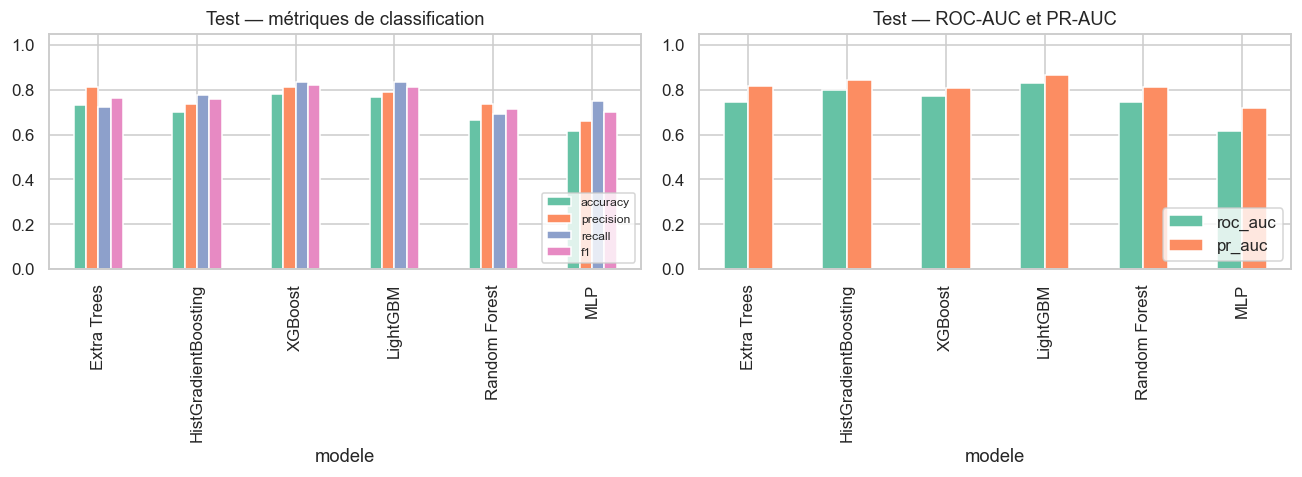

In [19]:
# Sélection du meilleur modèle : F1 validation, départage ROC-AUC
ranking = val_table.sort_values(["f1", "roc_auc"], ascending=False)
best_name = ranking.index[0]
print("Meilleur modèle (selon F1 validation) :", best_name)
display(ranking)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
test_table[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Test — métriques de classification")
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc="lower right", fontsize=8)
test_table[["roc_auc", "pr_auc"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Test — ROC-AUC et PR-AUC")
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_comparaison_test.png", bbox_inches="tight")
plt.show()


### Matrices de confusion (jeu de test)

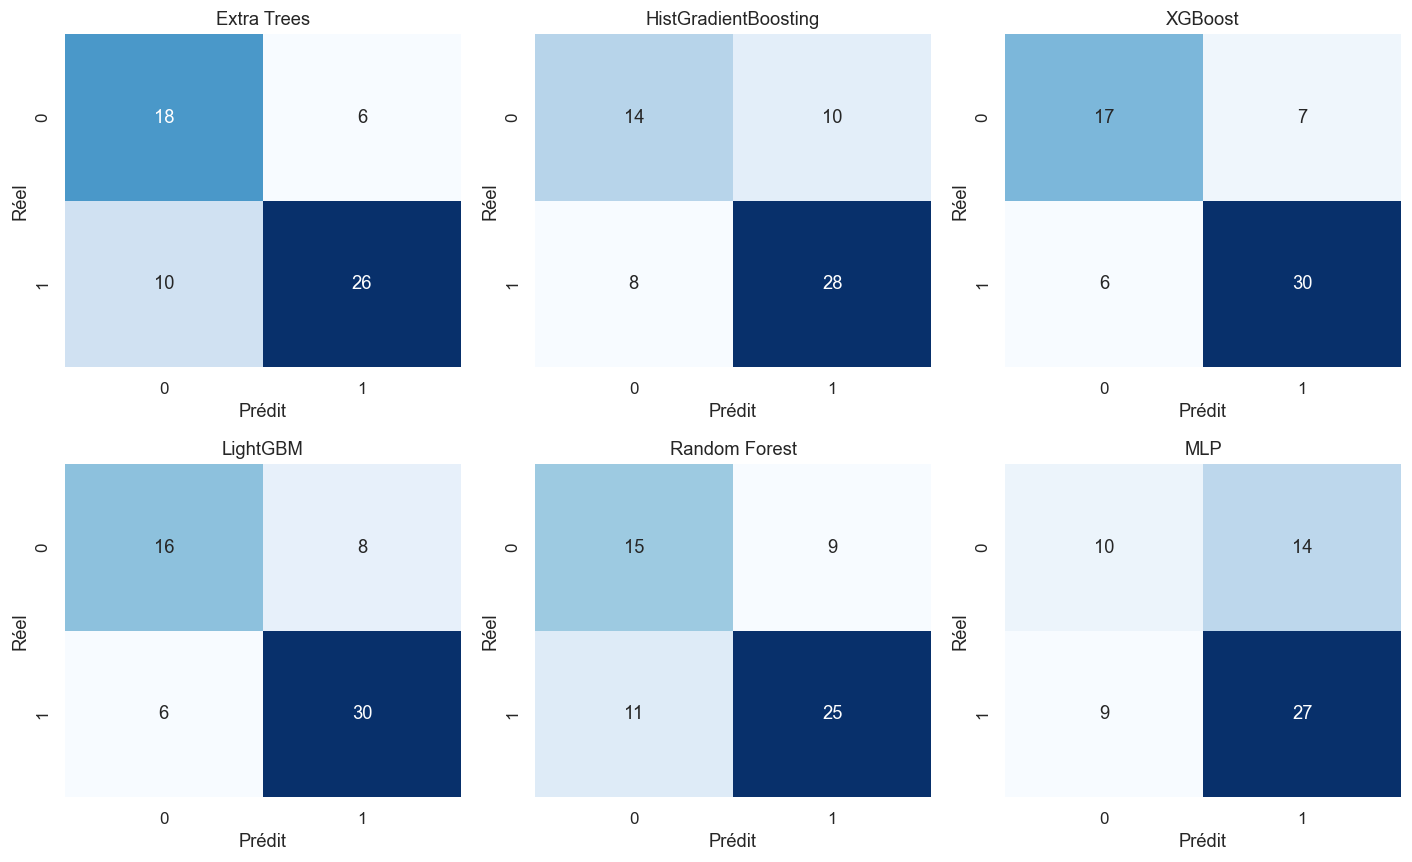

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, name in zip(axes.ravel(), models):
    pred = fitted[name].predict(X_test)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["0", "1"],
        yticklabels=["0", "1"],
        cbar=False,
    )
    ax.set_title(name)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_matrices_confusion.png", bbox_inches="tight")
plt.show()


In [16]:
from sklearn.model_selection import train_test_split

# Vérifier que le dataset est chargé
print(df.shape)

# Séparer les variables et la cible
X = df.drop(columns=["Fire", "acq_date", "acq_time"], errors="ignore")
y = df["Fire"]

# Créer les ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

NameError: name 'df' is not defined

In [15]:
import numpy as np
from imblearn.over_sampling import SMOTE

# 1. Data augmentation par bruit gaussien
def gaussian_augmentation(X, y, noise_scale=0.03, random_state=42):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    classes, counts = np.unique(y, return_counts=True)
    if len(classes) != 2:
        raise ValueError("Cette augmentation est prévue pour une cible à deux classes.")

    minority_class = classes[np.argmin(counts)]
    majority_count = counts.max()
    minority_X = X[y == minority_class]
    n_new = majority_count - len(minority_X)

    if n_new == 0:
        return X.copy(), y.copy()

    rng = np.random.default_rng(random_state)
    source_rows = minority_X[rng.integers(0, len(minority_X), size=n_new)]
    noise = rng.normal(
        loc=0,
        scale=noise_scale * X.std(axis=0),
        size=source_rows.shape
    )
    synthetic_X = np.clip(source_rows + noise, X.min(axis=0), X.max(axis=0))
    synthetic_y = np.full(n_new, minority_class, dtype=y.dtype)

    return np.vstack([X, synthetic_X]), np.concatenate([y, synthetic_y])

X_train_gaussian, y_train_gaussian = gaussian_augmentation(X_train, y_train)

# 2. Data balancing avec SMOTE
n_minority = np.unique(y_train, return_counts=True)[1].min()
if n_minority < 2:
    raise ValueError("SMOTE nécessite au moins deux exemples dans chaque classe.")

smote = SMOTE(
    random_state=42,
    k_neighbors=min(5, n_minority - 1)
)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Taille originale :", np.unique(y_train, return_counts=True))
print("Après Gaussian   :", np.unique(y_train_gaussian, return_counts=True))
print("Après SMOTE      :", np.unique(y_train_smote, return_counts=True))

NameError: name 'X_train' is not defined

## 7. SHAP et importance des variables

On explique le **meilleur modèle**. Pour les forêts / boosting, `TreeExplainer` ; pour le MLP, `Permutation` + `shap.Explainer` Kernel si besoin.


In [3]:
from sklearn.model_selection import train_test_split

# Séparer les variables explicatives et la cible
X = df.drop(columns=["Fire", "acq_date", "acq_time"], errors="ignore")
y = df["Fire"]

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

NameError: name 'df' is not defined

In [4]:
print("Nombre de lignes d'entraînement :", len(X_train))
print("Nombre de lignes de test :", len(X_test))

print("\nDistribution de Fire dans l'entraînement :")
print(y_train.value_counts())

print("\nDistribution de Fire dans le test :")
print(y_test.value_counts())

NameError: name 'X_train' is not defined

In [5]:

import numpy as np
import pandas as pd
import shap

from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from scipy.sparse import issparse

# ==========================================
# 1. GAUSSIAN DATA AUGMENTATION
# ==========================================

np.random.seed(42)

# Variables numériques continues adaptées au bruit gaussien
numeric_cols = [
    "humidity_percent",
    "precipitation_mm",
    "pressure_hPa",
    "temperature_C",
    "wind_speed_mps",
    "NDVI",
    "NDMI",
    "NDWI",
    "NBR"
]

# Conserver uniquement les colonnes disponibles
numeric_cols = [c for c in numeric_cols if c in X_train.columns]

# Créer une copie des données d'entraînement
X_gaussian = X_train.copy()

# Ajouter un faible bruit gaussien
noise_scale = 0.02

for col in numeric_cols:
    sigma = X_train[col].std()

    if pd.notna(sigma) and sigma > 0:
        noise = np.random.normal(
            loc=0,
            scale=noise_scale * sigma,
            size=len(X_train)
        )
        X_gaussian[col] = X_train[col] + noise

# Conserver des valeurs physiquement plausibles
if "humidity_percent" in X_gaussian.columns:
    X_gaussian["humidity_percent"] = (
        X_gaussian["humidity_percent"].clip(0, 100)
    )

if "precipitation_mm" in X_gaussian.columns:
    X_gaussian["precipitation_mm"] = (
        X_gaussian["precipitation_mm"].clip(lower=0)
    )

if "wind_speed_mps" in X_gaussian.columns:
    X_gaussian["wind_speed_mps"] = (
        X_gaussian["wind_speed_mps"].clip(lower=0)
    )

# Conserver les étiquettes Fire originales
X_train_aug = pd.concat(
    [X_train, X_gaussian],
    ignore_index=True
)

y_train_aug = pd.concat(
    [y_train.reset_index(drop=True),
     y_train.reset_index(drop=True)],
    ignore_index=True
)

print("=== Après Gaussian Augmentation ===")
print("Dimensions X :", X_train_aug.shape)
print("Distribution Fire :")
print(y_train_aug.value_counts())


# ==========================================
# 2. PREPROCESSING
# ==========================================

# Utiliser le préprocesseur déjà ajusté sur le train original
X_train_t = pre.transform(X_train_aug)
X_test_t = pre.transform(X_test)

# SMOTE et certains modèles nécessitent un format dense.
# Pour ce petit dataset, on peut convertir les matrices creuses.
if issparse(X_train_t):
    X_train_t = X_train_t.toarray()

if issparse(X_test_t):
    X_test_t = X_test_t.toarray()


# ==========================================
# 3. SMOTE : EQUILIBRAGE DES CLASSES
# ==========================================

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_t,
    y_train_aug
)

print("\n=== Après SMOTE ===")
print("Dimensions X :", X_train_smote.shape)
print("Distribution Fire :")
print(pd.Series(y_train_smote).value_counts())


# ==========================================
# 4. REENTRAINER LE MEILLEUR MODELE
# ==========================================

model = clone(model)

model.fit(X_train_smote, y_train_smote)

# Évaluation sur le test original, jamais augmenté
y_pred = model.predict(X_test_t)

print("\n=== Résultats sur le test ===")
print(classification_report(y_test, y_pred))
print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred))

# Garder les données rééchantillonnées pour SHAP
X_train_t = X_train_smote


NameError: name 'X_train' is not defined

,importance_native
num__pressure_hPa,197
num__longitude,177
num__wind_speed_mps,117
num__latitude,102
num__humidity_percent,73
num__precipitation_mm,69
num__vent_u,69
num__NDWI,68
num__NDMI,62
num__nbr_ndvi,60


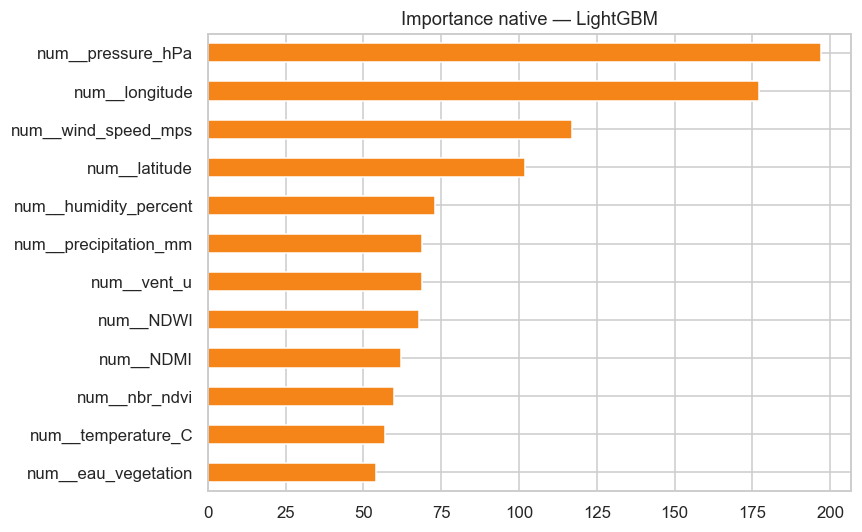

In [23]:
# Importance native (Gini / gain) si disponible
if hasattr(model, "feature_importances_"):
    native = pd.Series(model.feature_importances_, index=feat_names).sort_values(
        ascending=False
    )
    display(native.head(12).to_frame("importance_native"))
    plt.figure(figsize=(8, 5))
    native.head(12).iloc[::-1].plot(kind="barh", color="#f58518")
    plt.title(f"Importance native — {best_name}")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "11_importance_native.png", bbox_inches="tight")
    plt.show()


## 8. Analyse des erreurs du meilleur modèle

On compare faux positifs (alerte à tort) et faux négatifs (feu manqué) sur le **test**.


              precision    recall  f1-score   support

           0      0.727     0.667     0.696        24
           1      0.789     0.833     0.811        36

    accuracy                          0.767        60
   macro avg      0.758     0.750     0.753        60
weighted avg      0.765     0.767     0.765        60

type_erreur
TP                    30
TN                    16
FP (fausse alerte)     8
FN (feu manque)        6
Name: count, dtype: int64


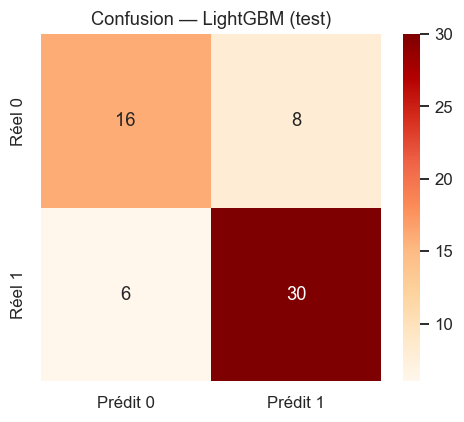

In [24]:
proba = best_pipe.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

err = X_test.copy()
err["y_true"] = y_test.values
err["y_pred"] = pred
err["proba"] = proba
err["type_erreur"] = np.select(
    [
        (err["y_true"] == 1) & (err["y_pred"] == 0),
        (err["y_true"] == 0) & (err["y_pred"] == 1),
        (err["y_true"] == 1) & (err["y_pred"] == 1),
        (err["y_true"] == 0) & (err["y_pred"] == 0),
    ],
    ["FN (feu manque)", "FP (fausse alerte)", "TP", "TN"],
    default="autre",
)

print(classification_report(y_test, pred, digits=3))
print(err["type_erreur"].value_counts())
err.to_csv(OUT_DIR / "erreurs_test.csv", index=False)

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="OrRd",
    xticklabels=["Prédit 0", "Prédit 1"],
    yticklabels=["Réel 0", "Réel 1"],
)
plt.title(f"Confusion — {best_name} (test)")
plt.tight_layout()
plt.savefig(FIG_DIR / "12_confusion_best.png", bbox_inches="tight")
plt.show()


Profil moyen par type d'erreur :


,temperature_C,humidity_percent,precipitation_mm,wind_speed_mps,NDVI,NDMI,NBR,mois,heure,stress_thermique
type_erreur,,,,,,,,,,
FN (feu manque),12.203,54.870,0.001,2.065,0.002,-0.016,0.008,1.333,7.500,6.451
FP (fausse alerte),15.302,58.755,0.001,1.547,0.222,0.081,0.180,2.500,7.500,7.667
TN,12.986,54.786,0.001,1.996,0.115,0.018,0.034,2.625,7.188,7.248
TP,13.992,57.976,0.001,1.806,0.328,-0.007,0.136,2.100,9.033,6.606


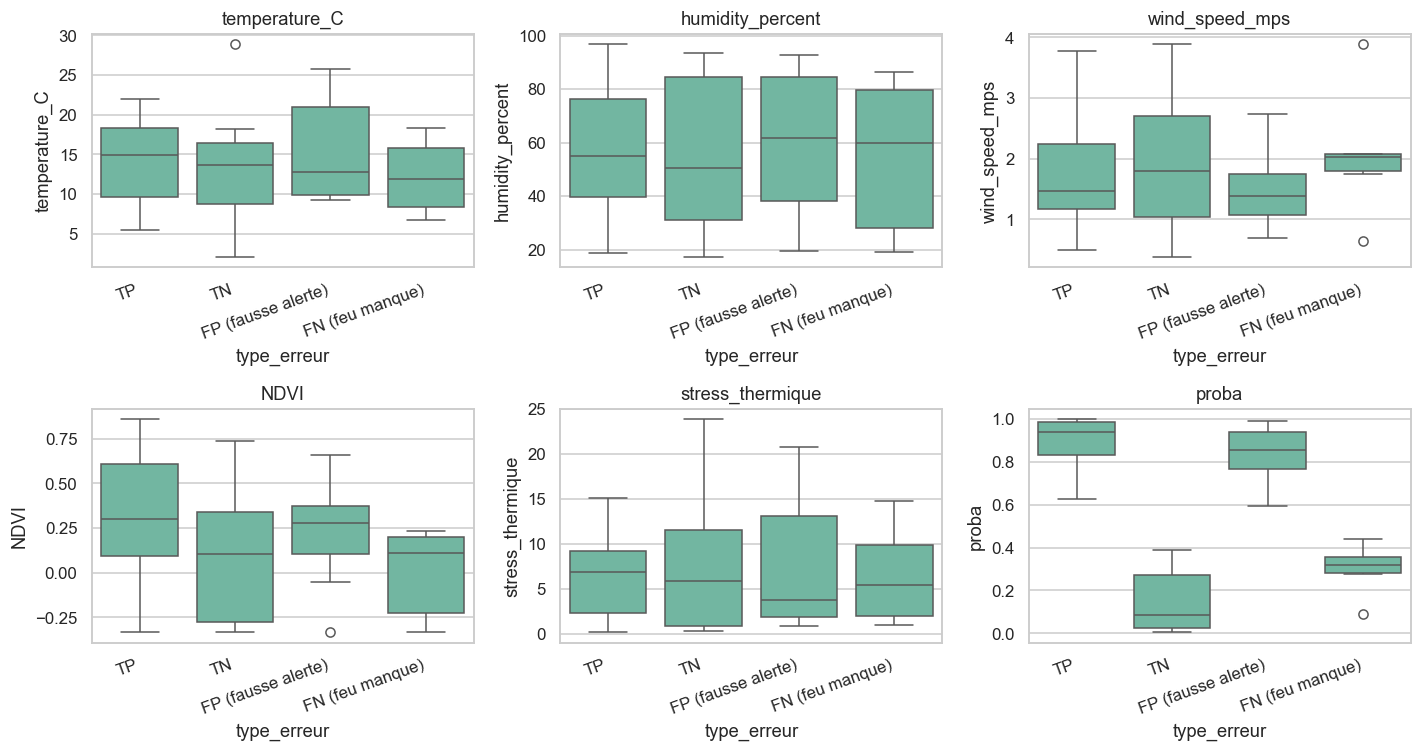

Cas les plus incertains (|proba - 0.5| minimal) :


,temperature_C,humidity_percent,precipitation_mm,wind_speed_mps,NDVI,NDMI,NBR,mois,heure,stress_thermique,y_true,y_pred,proba,type_erreur
9,6.738321,86.243979,0.000000,2.073021,0.115813,-0.158570,-0.056399,1,2,0.926925,1,0,0.441450,FN (feu manque)
188,25.747278,19.545691,0.000855,2.744345,0.660475,0.151933,0.388728,2,13,20.714794,0,1,0.595398,FP (fausse alerte)
70,11.740961,57.196837,0.002640,1.680024,-0.259259,0.224490,0.538462,1,13,5.025503,0,0,0.388845,TN
114,18.883981,52.621333,0.000000,2.092375,0.281213,-0.241464,-0.083174,2,13,8.946979,1,1,0.626904,TP
46,10.745721,82.506499,0.000000,3.886099,0.227552,-0.157806,-0.077634,1,2,1.879803,1,0,0.357386,FN (feu manque)
63,16.760538,48.296127,0.004284,0.646073,0.103257,-0.153726,-0.129635,1,13,8.665847,1,0,0.347477,FN (feu manque)
101,16.150552,20.414371,0.000852,3.379648,0.103220,-0.145654,-0.065749,2,13,12.853519,1,1,0.663471,TP
3,8.234415,39.120900,0.000000,0.543159,0.291355,-0.254314,-0.177430,1,2,5.013038,0,0,0.333431,TN


In [25]:
inspect_cols = [
    "temperature_C",
    "humidity_percent",
    "precipitation_mm",
    "wind_speed_mps",
    "NDVI",
    "NDMI",
    "NBR",
    "mois",
    "heure",
    "stress_thermique",
]
print("Profil moyen par type d'erreur :")
display(err.groupby("type_erreur")[inspect_cols].mean().round(3))

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(
    axes.ravel(),
    [
        "temperature_C",
        "humidity_percent",
        "wind_speed_mps",
        "NDVI",
        "stress_thermique",
        "proba",
    ],
):
    sns.boxplot(data=err, x="type_erreur", y=col, ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "13_erreurs_profils.png", bbox_inches="tight")
plt.show()

print("Cas les plus incertains (|proba - 0.5| minimal) :")
display(
    err.assign(marge=(err["proba"] - 0.5).abs())
    .nsmallest(8, "marge")[
        inspect_cols + ["y_true", "y_pred", "proba", "type_erreur"]
    ]
)


## 9. Synthèse

| Étape | Choix retenu | Pourquoi |
|---|---|---|
| Manquants | sentinelles −1 → NaN, puis médiane du **train** | pas de NaN bruts ; nodata satellite |
| Outliers | clip IQR appris sur le **train** | petit N : on ne supprime pas de lignes |
| Split | 60 / 20 / 20 stratifié | comparaison honnête, pas de fuite |
| Encodage | one-hot `saison`, `periode` + sin/cos temporels | cyclique + catégoriel |
| Scaling | StandardScaler **pour le MLP seulement** | les arbres n'en ont pas besoin |
| Sélection | F1 sur validation | équilibre FP / FN pour un risque incendie |
| Explicabilité | SHAP | variables réellement utilisées par le modèle |

Les figures sont dans `figures/` et les tableaux dans `outputs/`.
